In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
np.random.seed(0)

In [16]:
N = 200
p = 5

X = np.random.randn(N, p)
true_beta = np.array([1.5, -2.0, 0.8, 0.9, -0.1])
sigma = 1.0

y = X @ true_beta + np.random.normal(0, sigma, N)



# 対数尤度
$$
\mathrm{log}p(y | X, \beta, \sigma) = -\frac{N}{2}\mathrm{log}(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{i=1}^N (y_i-x_i^T\beta)^2
$$

# beta(重み)の事前分布
ここでは重みの事前分布について、平均0、分散$\tau^2$のガウス分布とする。
$$
\beta_j \sim N(0,\tau^2)
$$
1つの$\beta_j$は
$$
p(\beta_j)=\frac{1}{\sqrt{2\pi\tau^2}}\exp\left(-\frac{\beta_j^2}{2\tau^2}\right)
$$
$p$個が独立ならば
$$
p(\beta)=\prod_{j=1}^{p}p(\beta_j)
$$
よって事前分布は次のようになる。
$$
p(\beta)=(2\pi\tau^2)^{-p/2}\exp\left[-\frac{1}{2\tau^2}\sum_{j=1}^{p}\beta_j^2\right]
$$
対数事前分布は次のようになる。
$$
\log p(\beta)=-\frac{p}{2}\log(2\pi\tau^2)-\frac{1}{2\tau^2}\sum_{j=1}^{p}\beta_j^2
$$

# sigma(ノイズレベル)の事前分布
ここではノイズレベルとして半ガウス分布を使う。
$$
\sigma \sim \mathrm{Half\text{-}Normal}(0,s_{\sigma}^{2})
$$
よって正規化定数を無視するとlog 事前分布は
$$
\log p(\sigma)=-\frac{\sigma^2}{2s_{\sigma}^2}
$$

# 事後カーネル
事後カーネルは次のようになる。
$$
p(\beta,\sigma \mid y,X) \propto p(y \mid X,\beta,\sigma)p(\beta)p(\sigma)
$$
対数事後カーネルは次のようになる。
$$
\log p(\beta,\sigma \mid y,X)
\propto
\log p(y \mid X,\beta,\sigma)
+
\log p(\beta)
+
\log p(\sigma)
$$

In [17]:
tau = 10.0
sigma_prior_sd = 5.0

proposal_sd_beta = 0.05
proposal_sd_sigma = 0.05

# 対数尤度
def log_likelihood(beta, sigma):
	if sigma <= 0:
		return -np.inf

	residual = y - X @ beta

	return (
		-0.5 * N * np.log(2 * np.pi * sigma**2)
		-0.5 / sigma**2 * np.sum(residual**2)
	)

# 重みの事前分布
def log_prior_beta(beta):
	return (
		-0.5 * p * np.log(2 * np.pi * tau**2)
		-0.5 / tau**2 * np.sum(beta**2)
	)

# ノイズレベルの事前分布
def log_prior_sigma(sigma):
	if sigma <= 0:
		return -np.inf

	return -0.5 * sigma**2 / sigma_prior_sd**2

# 事後カーネル
def log_posterior(beta, sigma):
	return (
		log_likelihood(beta, sigma)
		+ log_prior_beta(beta)
		+ log_prior_sigma(sigma)
	)


# ランダムウォークMH 法を用いて更新

例えば$\beta$なら

現在$\beta^{(t)}$にいるとして、ランダムに次を提案する。
$$
\beta^* = \beta^{(t)} + e \\
e \sim N(0,s_p^2 I)
$$

そして、受容確率を計算する。ここでは、logをとって数値的に安定化させる。
$$
r=\frac{p(\beta^{*},\sigma^{(t)}\mid y,X)}{p(\beta^{(t)},\sigma^{(t)}\mid y,X)} \\
\log r
=
\log p(\beta^{*},\sigma^{(t)}\mid y,X)
-
\log p(\beta^{(t)},\sigma^{(t)}\mid y,X)
$$

In [18]:
n = 100000
burn_in = 10000

beta = np.zeros((n + 1, p))
sigma = np.zeros(n + 1)

beta[0] = np.zeros(p)
sigma[0] = 1.0

for t in range(n):
	# beta を更新
	beta_prop = beta[t] + np.random.normal(0, proposal_sd_beta, size=p)
	log_r_beta = log_posterior(beta_prop, sigma[t]) - log_posterior(beta[t], sigma[t])

	if np.log(np.random.rand()) < min(0, log_r_beta):
		beta[t + 1] = beta_prop
	else:
		beta[t + 1] = beta[t]

	# sigma を更新
	sigma_prop = sigma[t] + np.random.normal(0, proposal_sd_sigma)
	log_r_sigma = log_posterior(beta[t + 1], sigma_prop) - log_posterior(beta[t + 1], sigma[t])

	if np.log(np.random.rand()) < min(0, log_r_sigma):
		sigma[t + 1] = sigma_prop
	else:
		sigma[t + 1] = sigma[t]

In [19]:
beta_samples = beta[burn_in + 1:]
sigma_samples = sigma[burn_in + 1:]


print("beta mean:")
print(np.mean(beta_samples, axis=0))

print("sigma mean:")
print(np.mean(sigma_samples))

beta mean:
[ 1.4532725  -2.14802575  0.7983157   0.86272148 -0.08382178]
sigma mean:
0.9328993424822106


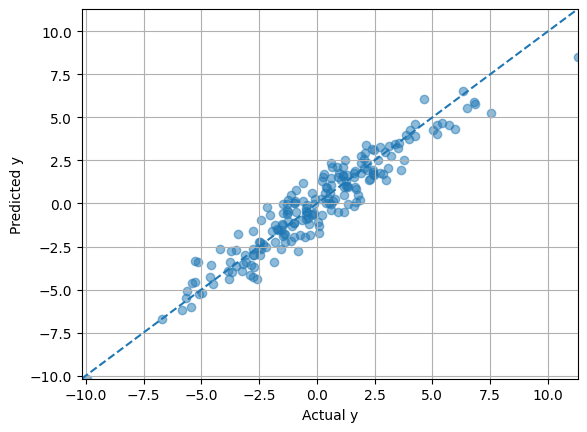

In [20]:
beta_mean = np.mean(beta_samples, axis=0)

y_pred = X @ beta_mean


plt.scatter(y, y_pred, alpha=0.5)

lower = min(y.min(), y_pred.min())
upper = max(y.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.xlim(lower, upper)
plt.ylim(lower, upper)
plt.xlabel("Actual y")
plt.ylabel("Predicted y")

plt.grid()
plt.show()